# Overall Evaluation

## 1. Introduction

This notebook provides an overall evaluation of the knowledge discovery process applied to the CBIS-DDSM clinical descriptors.

It brings together the results obtained in the previous stages:

- Data understanding and preparation.
- Association rule mining.
- Clustering analysis.
- Classification models.
- Semantic knowledge graph construction.

The objective is to summarize the results, compare the different approaches, and identify their strengths and limitations.

The evaluation focuses on the experimental results obtained from clinical descriptors and does not aim to provide a clinical diagnosis.

In [1]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

DATA_PATH = "../data/processed"

mass_rules = pd.read_csv(os.path.join(DATA_PATH, "mass_selected_rules.csv"))
calc_rules = pd.read_csv(os.path.join(DATA_PATH, "calc_selected_rules.csv"))

mass_clusters = np.load(os.path.join(DATA_PATH, "mass_clusters.npy"))
calc_clusters = np.load(os.path.join(DATA_PATH, "calc_clusters.npy"))

mass_knowledge_graph = nx.read_graphml(
    os.path.join(DATA_PATH, "mass_knowledge_graph.graphml")
)

calc_knowledge_graph = nx.read_graphml(
    os.path.join(DATA_PATH, "calc_knowledge_graph.graphml")
)

mass_y_test = np.load(os.path.join(DATA_PATH, "mass_y_test.npy"))
calc_y_test = np.load(os.path.join(DATA_PATH, "calc_y_test.npy"))

print("Previous results loaded successfully.")

print("\nMass dataset:")
print("Selected rules:", len(mass_rules))
print("Training clusters:", len(mass_clusters))
print("Knowledge graph:", mass_knowledge_graph.number_of_nodes(), "nodes,",
      mass_knowledge_graph.number_of_edges(), "edges")
print("Test samples:", len(mass_y_test))

print("\nCalcification dataset:")
print("Selected rules:", len(calc_rules))
print("Training clusters:", len(calc_clusters))
print("Knowledge graph:", calc_knowledge_graph.number_of_nodes(), "nodes,",
      calc_knowledge_graph.number_of_edges(), "edges")
print("Test samples:", len(calc_y_test))

Previous results loaded successfully.

Mass dataset:
Selected rules: 10
Training clusters: 1054
Knowledge graph: 21 nodes, 36 edges
Test samples: 264

Calcification dataset:
Selected rules: 11
Training clusters: 1237
Knowledge graph: 25 nodes, 36 edges
Test samples: 309


## 2. Classification Performance

This section summarizes the performance of the classification models evaluated in Notebook 05.

Two machine learning algorithms were compared:

- Logistic Regression
- Random Forest

The evaluation considers accuracy, macro precision, macro recall, and macro F1-score.

These metrics provide complementary information about the models' performance across the three pathology classes.

In [3]:
classification_results = pd.DataFrame([
    {
        "Dataset": "Mass",
        "Model": "Logistic Regression",
        "Accuracy": 0.814,
        "Macro Precision": 0.810,
        "Macro Recall": 0.746,
        "Macro F1-score": 0.771
    },
    {
        "Dataset": "Mass",
        "Model": "Random Forest",
        "Accuracy": 0.746,
        "Macro Precision": 0.680,
        "Macro Recall": 0.737,
        "Macro F1-score": 0.699
    },
    {
        "Dataset": "Calcification",
        "Model": "Logistic Regression",
        "Accuracy": 0.699,
        "Macro Precision": 0.704,
        "Macro Recall": 0.710,
        "Macro F1-score": 0.700
    },
    {
        "Dataset": "Calcification",
        "Model": "Random Forest",
        "Accuracy": 0.647,
        "Macro Precision": 0.651,
        "Macro Recall": 0.661,
        "Macro F1-score": 0.654
    }
])

print (classification_results.round(3))

         Dataset                Model  Accuracy  Macro Precision  \
0           Mass  Logistic Regression     0.814            0.810   
1           Mass        Random Forest     0.746            0.680   
2  Calcification  Logistic Regression     0.699            0.704   
3  Calcification        Random Forest     0.647            0.651   

   Macro Recall  Macro F1-score  
0         0.746           0.771  
1         0.737           0.699  
2         0.710           0.700  
3         0.661           0.654  


## 3. Classification Model Comparison

The following visualization compares Logistic Regression and Random Forest across the Mass and Calcification datasets.

The comparison uses accuracy and macro F1-score to evaluate overall predictive performance while accounting for class balance.

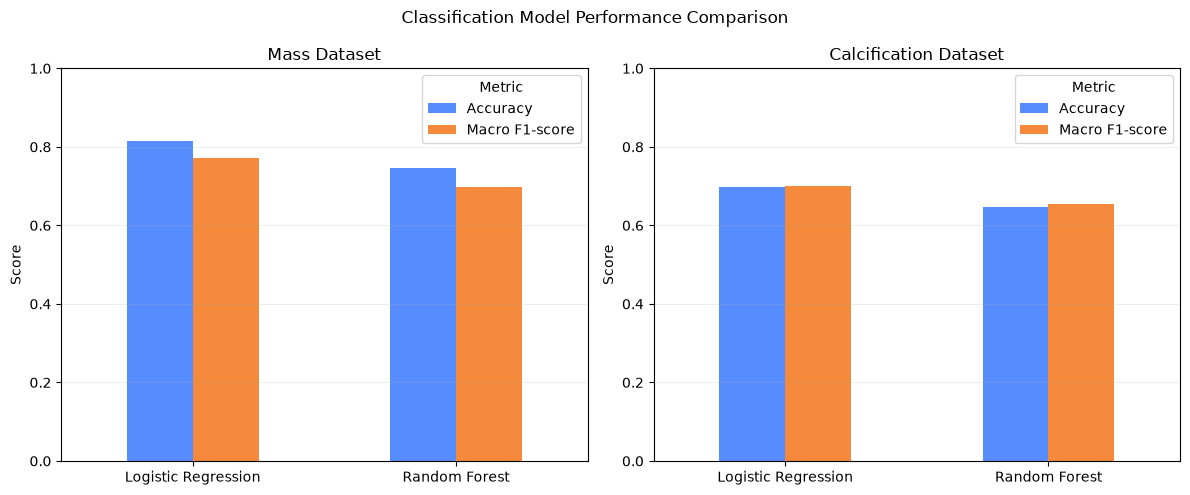

In [4]:
metrics = ["Accuracy", "Macro F1-score"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, dataset in zip(axes, ["Mass", "Calcification"]):
    data = classification_results[
        classification_results["Dataset"] == dataset
    ]

    data.set_index("Model")[metrics].plot(
        kind="bar",
        ax=ax,
        ylim=(0, 1),
        rot=0
    )

    ax.set_title(f"{dataset} Dataset")
    ax.set_ylabel("Score")
    ax.set_xlabel("")
    ax.legend(title="Metric")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Classification Model Performance Comparison")
plt.tight_layout()
plt.show()

## 4. Clustering Analysis

This section summarizes the clustering results obtained using K-Means in Notebook 04.

Four clusters were selected for each dataset. The clustering process used clinical features without including the pathology target.

Pathology labels were then used separately to examine the composition of each cluster and understand the patterns captured by the algorithm.

In [6]:
cluster_results = pd.DataFrame([
    {
        "Dataset": "Mass",
        "Number of Clusters": len(np.unique(mass_clusters)),
        "Number of Training Samples": len(mass_clusters)
    },
    {
        "Dataset": "Calcification",
        "Number of Clusters": len(np.unique(calc_clusters)),
        "Number of Training Samples": len(calc_clusters)
    }
])

print (cluster_results)

         Dataset  Number of Clusters  Number of Training Samples
0           Mass                   4                        1054
1  Calcification                   4                        1237


### 4.1 Cluster Distribution

This subsection examines the number of observations assigned to each cluster.

The distribution helps identify whether the clusters are relatively balanced or whether some groups contain substantially more observations than others.

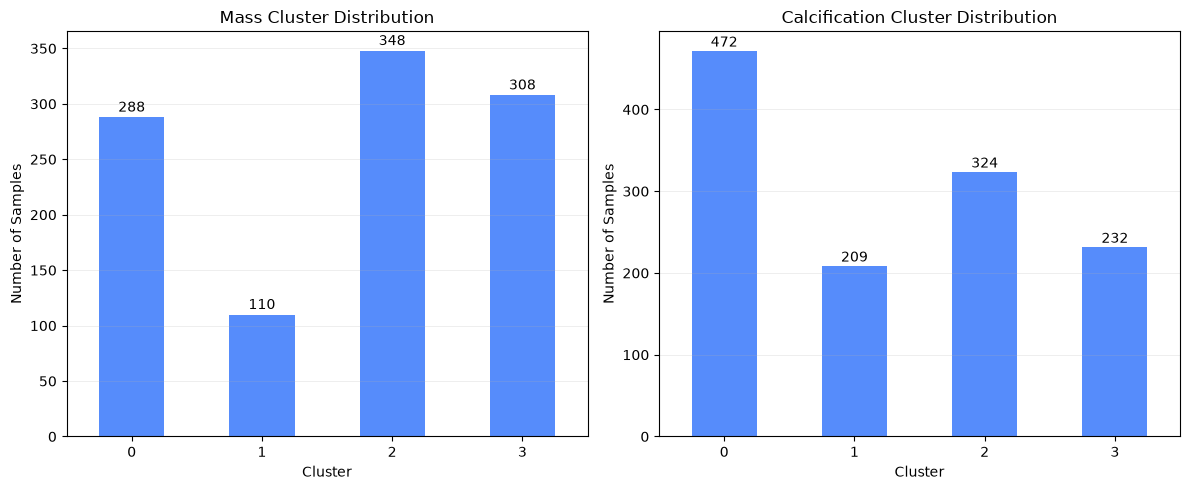

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, clusters, dataset in zip(
    axes,
    [mass_clusters, calc_clusters],
    ["Mass", "Calcification"]
):
    counts = pd.Series(clusters).value_counts().sort_index()

    counts.plot(kind="bar", ax=ax, rot=0)

    ax.set_title(f"{dataset} Cluster Distribution")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Number of Samples")
    ax.grid(axis="y", alpha=0.3)

    for i, value in enumerate(counts):
        ax.text(i, value + 5, str(value), ha="center")

plt.tight_layout()
plt.show()

### 4.2 Cluster Composition by Pathology

After clustering, pathology labels are used to examine the composition of each cluster.

This post-clustering analysis helps identify whether certain clusters are associated with a higher proportion of specific pathology categories.

Pathology was not used during K-Means training; it is only used here for interpretation.

In [10]:
import pandas as pd
import numpy as np
import os

DATA_PATH = "../data"
PROCESSED_PATH = "../data/processed"

# Load original datasets
mass_df = pd.read_csv(os.path.join(DATA_PATH, "mass_case_description_train_set.csv"))
calc_df = pd.read_csv(os.path.join(DATA_PATH, "calc_case_description_train_set.csv"))

# Load training indices and clustering results
mass_train_idx = np.load(os.path.join(PROCESSED_PATH, "mass_train_idx.npy"))
calc_train_idx = np.load(os.path.join(PROCESSED_PATH, "calc_train_idx.npy"))

mass_clusters = np.load(os.path.join(PROCESSED_PATH, "mass_clusters.npy"))
calc_clusters = np.load(os.path.join(PROCESSED_PATH, "calc_clusters.npy"))

# Reconstruct training datasets
mass_train_df = mass_df.iloc[mass_train_idx].copy()
calc_train_df = calc_df.iloc[calc_train_idx].copy()

# Analyze cluster composition
def analyze_cluster_composition(df, clusters, dataset):
    results = pd.crosstab(
        clusters,
        df["pathology"],
        normalize="index"
    ) * 100

    print(f"\n{dataset} - Pathology distribution by cluster (%)")
    print (results.round(2))

    return results

mass_cluster_composition = analyze_cluster_composition(
    mass_train_df, mass_clusters, "Mass"
)

calc_cluster_composition = analyze_cluster_composition(
    calc_train_df, calc_clusters, "Calcification"
)


Mass - Pathology distribution by cluster (%)
pathology  BENIGN  BENIGN_WITHOUT_CALLBACK  MALIGNANT
row_0                                                
0            5.56                     2.78      91.67
1           83.64                     0.00      16.36
2           62.36                    19.83      17.82
3           44.16                     1.95      53.90

Calcification - Pathology distribution by cluster (%)
pathology  BENIGN  BENIGN_WITHOUT_CALLBACK  MALIGNANT
row_0                                                
0           56.14                     0.00      43.86
1           10.53                    76.08      13.40
2           37.96                     1.54      60.49
3            5.60                    92.67       1.72


### 4.3 Pathology Composition Across Clusters

The following charts show the percentage distribution of pathology categories within each cluster.

This visualization provides a clearer comparison of the cluster composition for Mass and Calcification datasets.

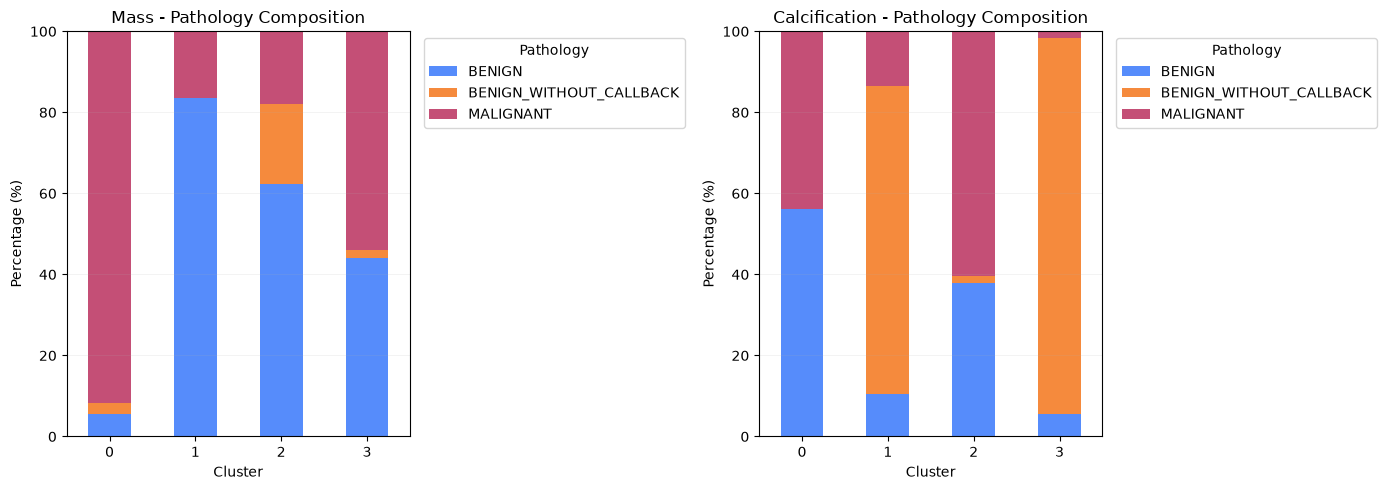

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, composition, dataset in zip(
    axes,
    [mass_cluster_composition, calc_cluster_composition],
    ["Mass", "Calcification"]
):
    composition.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        rot=0
    )

    ax.set_title(f"{dataset} - Pathology Composition")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Percentage (%)")
    ax.set_ylim(0, 100)
    ax.legend(title="Pathology", bbox_to_anchor=(1.02, 1))
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

## 5. Association Rules Evaluation

This section summarizes the representative association rules extracted from the Mass and Calcification datasets.

The rules were selected using three statistical measures:

- Support: how frequently an itemset appears in the dataset.
- Confidence: how frequently the consequent appears when the antecedent is present.
- Lift: how much stronger the association is compared with independent occurrence.

These measures help identify recurring relationships between clinical descriptors. They do not establish causality or clinical significance.

In [16]:
rule_summary = pd.DataFrame([
    {
        "Dataset": "Mass",
        "Selected Rules": len(mass_rules),
        "Average Support": mass_rules["Support"].mean(),
        "Average Confidence": mass_rules["Confidence"].mean(),
        "Average Lift": mass_rules["Lift"].mean()
    },
    {
        "Dataset": "Calcification",
        "Selected Rules": len(calc_rules),
        "Average Support": calc_rules["Support"].mean(),
        "Average Confidence": calc_rules["Confidence"].mean(),
        "Average Lift": calc_rules["Lift"].mean()
    }
])

print (rule_summary.round(3))

         Dataset  Selected Rules  Average Support  Average Confidence  \
0           Mass              10            0.063               0.811   
1  Calcification              11            0.063               0.862   

   Average Lift  
0         3.012  
1         2.045  


### 5.1 Association Rules Comparison

The following visualization compares the average support, confidence, and lift of the selected association rules for both datasets.

It provides a compact overview of the statistical strength and frequency of the selected patterns.

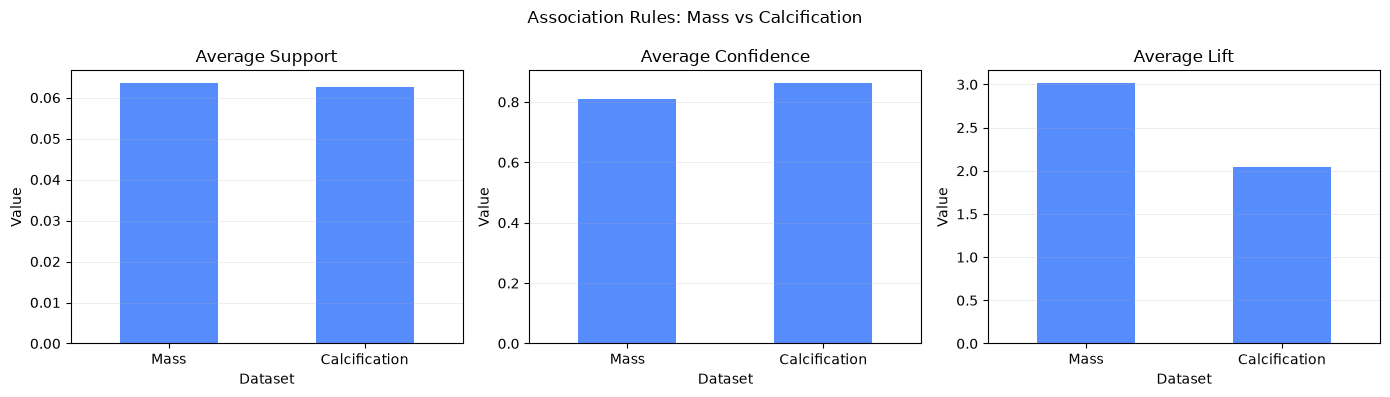

In [17]:
metrics = [
    "Average Support",
    "Average Confidence",
    "Average Lift"
]

comparison = rule_summary.set_index("Dataset")[metrics]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, metric in zip(axes, metrics):
    comparison[metric].plot(kind="bar", ax=ax, rot=0)

    ax.set_title(metric)
    ax.set_ylabel("Value")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Association Rules: Mass vs Calcification")
plt.tight_layout()
plt.show()

## 6. Semantic Knowledge Graph Evaluation

This section evaluates the compact semantic knowledge graphs constructed in Notebook 06.

Each graph represents selected association rules using:
- Clinical feature nodes representing rule antecedents and consequents.
- Association rule nodes connecting these features.
- Directed edges representing antecedent and consequent relationships.

The graph structure preserves the statistical metrics of each selected rule, including support, confidence, lift, and rule level.

In [19]:
graph_summary = pd.DataFrame([
    {
        "Dataset": "Mass",
        "Nodes": mass_knowledge_graph.number_of_nodes(),
        "Edges": mass_knowledge_graph.number_of_edges(),
        "Feature Nodes": sum(
            data.get("node_type") == "clinical_feature"
            for _, data in mass_knowledge_graph.nodes(data=True)
        ),
        "Rule Nodes": sum(
            data.get("node_type") == "association_rule"
            for _, data in mass_knowledge_graph.nodes(data=True)
        )
    },
    {
        "Dataset": "Calcification",
        "Nodes": calc_knowledge_graph.number_of_nodes(),
        "Edges": calc_knowledge_graph.number_of_edges(),
        "Feature Nodes": sum(
            data.get("node_type") == "clinical_feature"
            for _, data in calc_knowledge_graph.nodes(data=True)
        ),
        "Rule Nodes": sum(
            data.get("node_type") == "association_rule"
            for _, data in calc_knowledge_graph.nodes(data=True)
        )
    }
])

print (graph_summary)

         Dataset  Nodes  Edges  Feature Nodes  Rule Nodes
0           Mass     21     36             11          10
1  Calcification     25     36             14          11


### 6.1 Semantic Graph Structure Comparison

The following chart compares the structural size of the two semantic knowledge graphs.

It highlights the number of nodes, edges, clinical feature nodes, and association rule nodes in each graph.

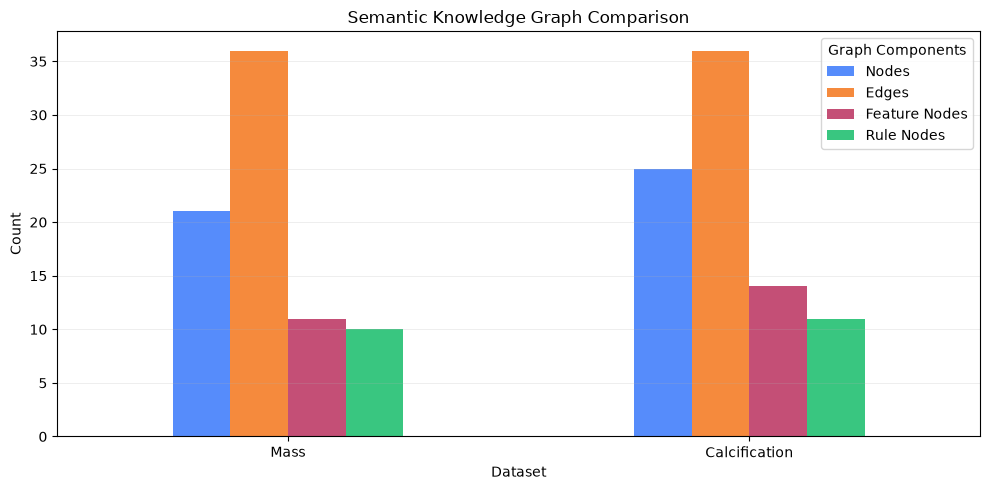

In [20]:
graph_metrics = graph_summary.set_index("Dataset")

ax = graph_metrics.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Semantic Knowledge Graph Comparison")
ax.set_xlabel("Dataset")
ax.set_ylabel("Count")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Graph Components")

plt.tight_layout()
plt.show()

## 7. Overall Evaluation

The project combines several knowledge discovery techniques to analyze the clinical descriptors of the CBIS-DDSM dataset.

The main findings are:

- **Association Rule Mining:** identified recurring relationships between clinical descriptors, with different patterns across Mass and Calcification datasets.
- **Clustering:** revealed groups with different pathology compositions, although the clusters do not perfectly separate the pathology categories.
- **Classification:** Logistic Regression achieved better overall performance than Random Forest on both datasets.
- **Semantic Knowledge Graphs:** transformed selected association rules into structured representations, making their relationships easier to explore.

The results show that combining data mining and machine learning techniques provides complementary perspectives on clinical descriptor data.

However, the findings remain experimental. They are limited by the available descriptors, class distributions, and model performance, and should not be interpreted as clinical conclusions.

## 8. Conclusion

This project implemented a complete knowledge discovery workflow using clinical descriptors from the CBIS-DDSM dataset.

Starting with data understanding and preparation, the workflow progressed through association rule mining, clustering, classification, and semantic knowledge graph construction.

The main outcome is a collection of structured results, trained models, statistical patterns, and graph representations that can be integrated into a web-based exploration interface.

The project demonstrates how multiple data mining techniques can be combined to extract, analyze, and organize knowledge from structured clinical data.

Future work will focus on integrating these outputs into an interactive HTML, CSS, and JavaScript interface and improving the evaluation of the resulting system.